### <center>**Logistic regression**

#### <center>**Бинарная классификация**

Логистическая регрессия (Logistic Regression) — одна из простейших моделей для решения задачи классификации. Несмотря на простоту, модель входит в топ часто используемых алгоритмов классификации в Data Science.

В основе логистической регрессии лежит логистическая функция (logistic function)  — отсюда и название модели. Однако более распространённое название этой функции — сигмόида (sigmoid). Записывается она следующим образом:

### <center>**σ(z) = 1 / (1 + e^(-z))**

где: 
* e = 2.718

![График зависимости сигмоиды от аргумента z.png](<attachment:График зависимости сигмоиды от аргумента z.png>)

Основная идея модели логистической регрессии: возьмём модель линейной регрессии (обозначим её выход за z):

![Модель линейной регрессии.png](<attachment:Модель линейной регрессии.png>)

и подставим выход модели  в функцию сигмоиды, чтобы получить искомые оценки вероятности (в математике принято писать оценочные величины с «шапкой» наверху, а истинные значения — без «шапки», это чистая формальность):

![Формула оценки вероятности принадлежности к классу.png](<attachment:Формула оценки вероятности принадлежности к классу.png>)

![Логистическая регрессия для бинарной классификации.png](<attachment:Логистическая регрессия для бинарной классификации.png>)
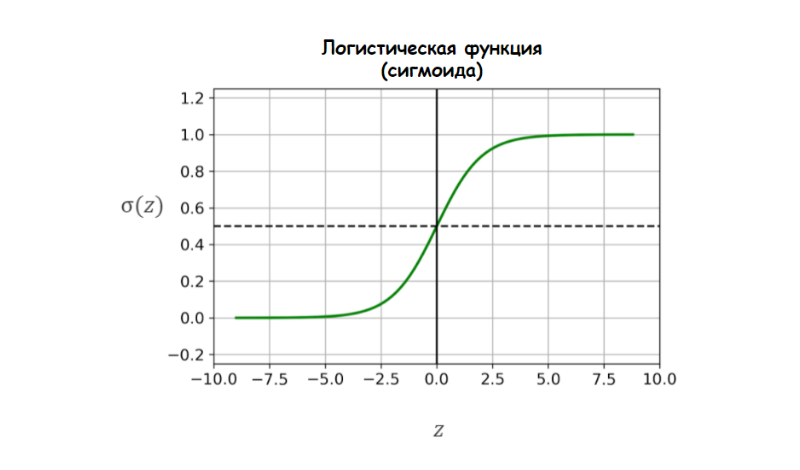
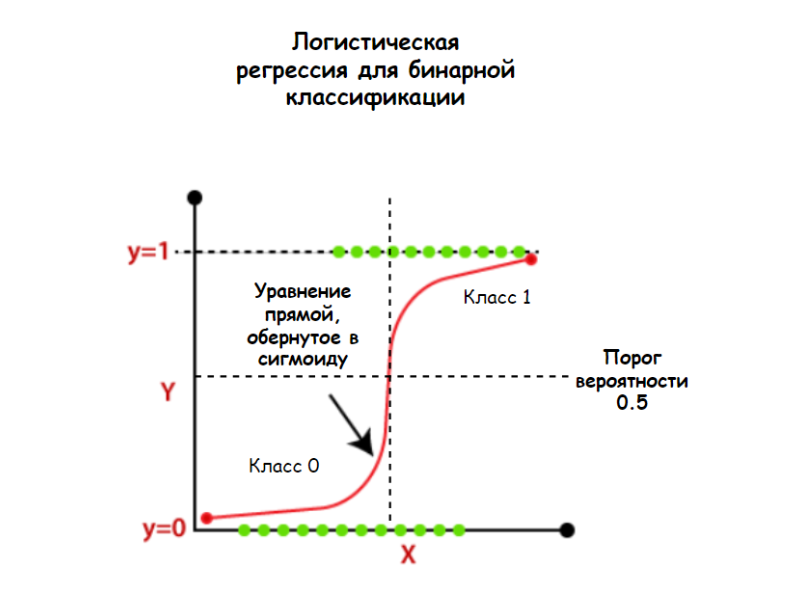
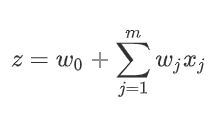
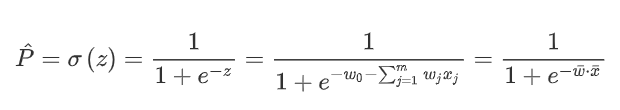

#### <center>**ПОИСК ПАРАМЕТРОВ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ**

Метод максимального правдоподобия (Maximum Likelihood Estimation — MLE)

Правдоподобие — это оценка того, насколько вероятно получить истинное значение целевой переменной y при данных  x и параметрах w. 

![Формула правдоподобия.png](<attachment:Формула правдоподобия.png>)

Где:
* n - количество наблюдений
* $y_i$ - это истинный класс (1 или 0) для i-ого объекта из набора данных.
* $P_i = σ(z_i)$ - предсказанная с помощью логистической регрессии вероятность принадлежности к классу 1 для i-ого объекта из набора данных.
* $z_i$ - результат подстановки i-ого объекта из набора данных в уравнение разделяющей плоскости $z_i = w * x_i$.
* log - логарифм (обычно используется натуральный логарифм по основанию e-ln).

![Функция логистических потерь.png](<attachment:Функция логистических потерь.png>)
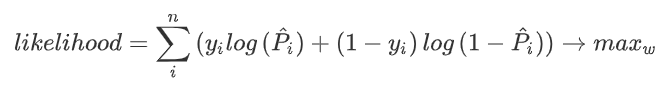
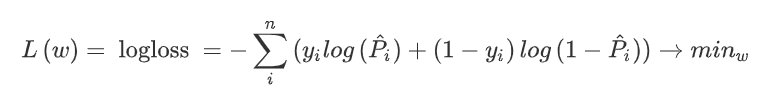

### <center> **ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ В SKLEARN**

In [17]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn import linear_model

In [18]:
diabetes = pd.read_csv('data/diabetes_cleaned.csv')
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,98.0,58.0,33.0,34.0,0.430,43,0
1,2,112.0,75.0,32.0,35.7,0.148,21,0
2,2,108.0,64.0,29.0,30.8,0.158,21,0
3,8,107.0,80.0,29.0,24.6,0.856,34,0
4,7,136.0,90.0,29.0,29.9,0.210,50,0


<Axes: >

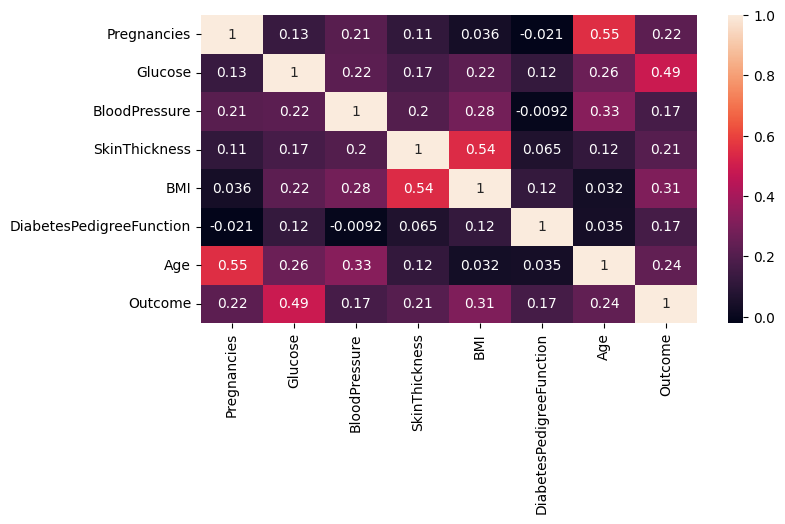

In [19]:
fig, ax = plt.subplots(figsize = (8, 4))
sns.heatmap(diabetes.corr(), annot=True)

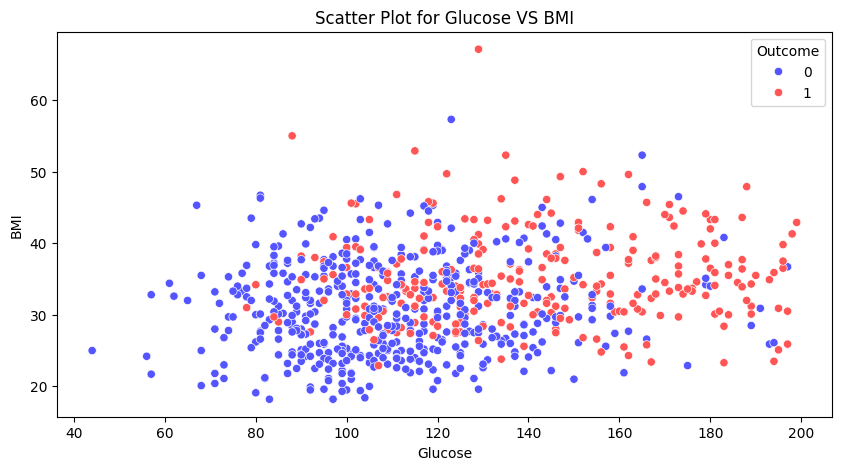

In [20]:
fig, ax = plt.subplots(figsize = (10, 5)) #фигура + координатная плоскость
#Строим диаграмму рассеяния
sns.scatterplot(
    data=diabetes, #датасет
    x='Glucose', #ось абсцисс
    y='BMI', #ось ординат
    hue='Outcome', #группировка
    palette='seismic', #палитра
    ax=ax, #координатная плоскость
);

#Задаём название графику
ax.set_title('Scatter Plot for Glucose VS BMI');

#### Основные параметры LogisticRegression:

* random_state — число, на основе которого происходит генерация случайных чисел.
* penalty — метод регуляризации. Возможные значения:
    * 'l1' — L1-регуляризация;
    * 'l2' — L2-регуляризация (используется по умолчанию);
    * 'elasticnet' — эластичная сетка (L1+L2);
    * 'None' — отсутствие регуляризации.
* C — коэффициент обратный коэффициенту регуляризации, то есть равен . Чем больше C, тем меньше регуляризация. По умолчанию C=1, тогда α=1.
* solver — численный метод оптимизации функции потерь logloss, может быть:
    * 'sag' — стохастический градиентный спуск (нужна стандартизация/нормализация);
    * 'saga' — модификация предыдущего, которая поддерживает работу с негладкими функциями (нужна стандартизация/нормализация);
    * 'newton-cg' — метод Ньютона с модификацией сопряжённых градиентов (не нужна стандартизация/нормализация);
    * 'lbfgs' — метод Бройдена — Флетчера — Гольдфарба — Шанно (не нужна стандартизация/нормализация; используется по умолчанию, так как из всех методов теоретически обеспечивает наилучшую сходимость);
    * 'liblinear' — метод покоординатного спуска (не нужна стандартизация/нормализация).
* max_iter — максимальное количество итераций, выделенных на сходимость.

In [21]:
# split the data into training and testing sets
X = diabetes[['Glucose', 'BMI']]
y = diabetes['Outcome']
# logistic regression model
log_reg = linear_model.LogisticRegression(random_state=42)
log_reg.fit(X, y)
print("W0:", round(log_reg.intercept_[0], 2))
print("W1, W2, WN:", [round(coef, 2) for coef in log_reg.coef_[0]])

W0: -8.25
W1, W2, WN: [np.float64(0.04), np.float64(0.09)]


In [22]:
# new patient
new_patient_0 = pd.DataFrame({'Glucose': [120], 'BMI': [30]})
new_patient_1 = pd.DataFrame({'Glucose': [180], 'BMI': [51]})
# prediction of probability of diabetes for new patients
prediction_0 = log_reg.predict_proba(new_patient_0)
prediction_1 = log_reg.predict_proba(new_patient_1)
# print the predictions 
print("Prediction for new patient 0:", round(prediction_0[0][1], 2)) 
print("Prediction for new patient 1:", round(prediction_1[0][1], 2))
# prediction of probability to class 
prediction_0_class = log_reg.predict(new_patient_0)
prediction_1_class = log_reg.predict(new_patient_1)
print("Predicted class for new patient 0:", prediction_0_class[0])
print("Predicted class for new patient 1:", prediction_1_class[0])

Prediction for new patient 0: 0.25
Prediction for new patient 1: 0.95
Predicted class for new patient 0: 0
Predicted class for new patient 1: 1


#### **plot_probabilities_2d()**

* X — матрица с наблюдениями,
* y — столбец с правильными ответами,
* model — модель, с помощью которой делается предсказание вероятностей.

In [23]:
#Функция для визуализации модели
def plot_probabilities_2d(X, y, model):
    #Генерируем координатную сетку из всех возможных значений для признаков
    #Glucose изменяется от x1_min = 44 до x2_max = 199, 
    #BMI — от x2_min = 18.2 до x2_max = 67.1
    #Результат работы функции — два массива xx1 и xx2, которые образуют координатную сетку
    xx1, xx2 = np.meshgrid(
        np.arange(X.iloc[:, 0].min()-1, X.iloc[:, 0].max()+1, 0.1),
        np.arange(X.iloc[:, 1].min()-1, X.iloc[:, 1].max()+1, 0.1)
    )
    #Вытягиваем каждый из массивов в вектор-столбец — reshape(-1, 1)
    #Объединяем два столбца в таблицу с помощью hstack
    X_net = np.hstack([xx1.reshape(-1, 1), xx2.reshape(-1, 1)])
    #Предсказываем вероятность для всех точек на координатной сетке
    #Нам нужна только вероятность класса 1
    probs = model.predict_proba(X_net)[:, 1]
    #Переводим столбец из вероятностей в размер координатной сетки
    probs = probs.reshape(xx1.shape)
    #Создаём фигуру и координатную плоскость
    fig, ax = plt.subplots(figsize = (10, 5))
    #Рисуем тепловую карту вероятностей
    contour = ax.contourf(xx1, xx2, probs, 100, cmap='bwr')
    #Рисуем разделяющую плоскость — линию, где вероятность равна 0.5
    bound = ax.contour(xx1, xx2, probs, [0.5], linewidths=2, colors='black');
    #Добавляем цветовую панель 
    colorbar = fig.colorbar(contour)
    #Накладываем поверх тепловой карты диаграмму рассеяния
    sns.scatterplot(x=X.iloc[:, 0], y=X.iloc[:, 1], hue=y, palette='seismic', ax=ax)
    #Даём графику название
    ax.set_title('Scatter Plot with Decision Boundary');
    #Смещаем легенду в верхний левый угол вне графика
    ax.legend(bbox_to_anchor=(-0.05, 1))

c:\Users\Romanov Roman\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


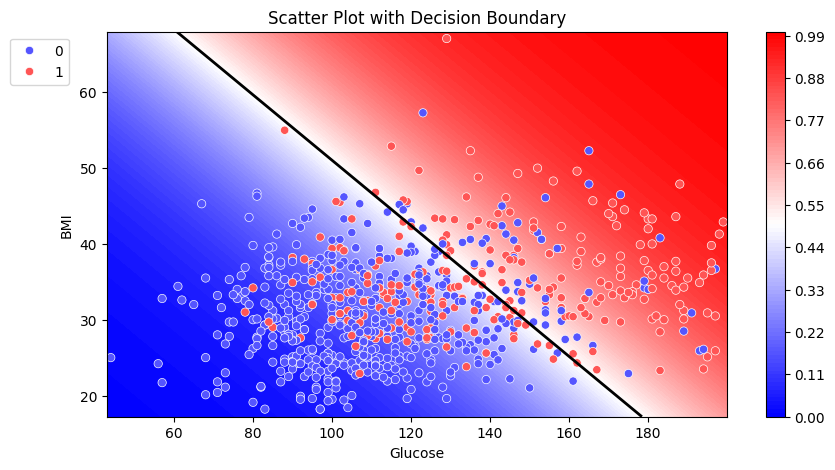

In [24]:
plot_probabilities_2d(X, y, log_reg)

In [25]:
#Создаём матрицу признаков X и столбец с ответами y
X = diabetes.drop('Outcome', axis=1)
y = diabetes['Outcome']
#Создаём объект класса LogisticRegression
log_reg_full = linear_model.LogisticRegression(random_state=42, max_iter=1000)
#Обучаем модель, минимизируя logloss
log_reg_full.fit(X, y)
#Делаем предсказание класса
y_pred = log_reg_full.predict(X)

In [26]:
#Создадим временную таблицу X
X_temp = X.copy()
#Добавим в эту таблицу результат предсказания
X_temp['Prediction'] = y_pred
X_temp.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,BMI,DiabetesPedigreeFunction,Age,Prediction
752,5,139.0,64.0,35.0,28.6,0.411,26,0
753,1,96.0,122.0,29.0,22.4,0.207,27,0
754,10,101.0,86.0,37.0,45.6,1.136,38,1
755,0,141.0,72.0,29.0,42.4,0.205,29,1
756,0,125.0,96.0,29.0,22.5,0.262,21,0


#### <center>**РАСЧЁТ МЕТРИК НА PYTHON**

* confusion_matrix() — расчёт матрицы ошибок,
* accuracy_score() — расчёт accuracy,
* precision_score() — расчёт precision,
* recall_score() — расчёт recall,
* f1_score() — расчёт $F_1$-меры.


In [27]:
from sklearn import metrics

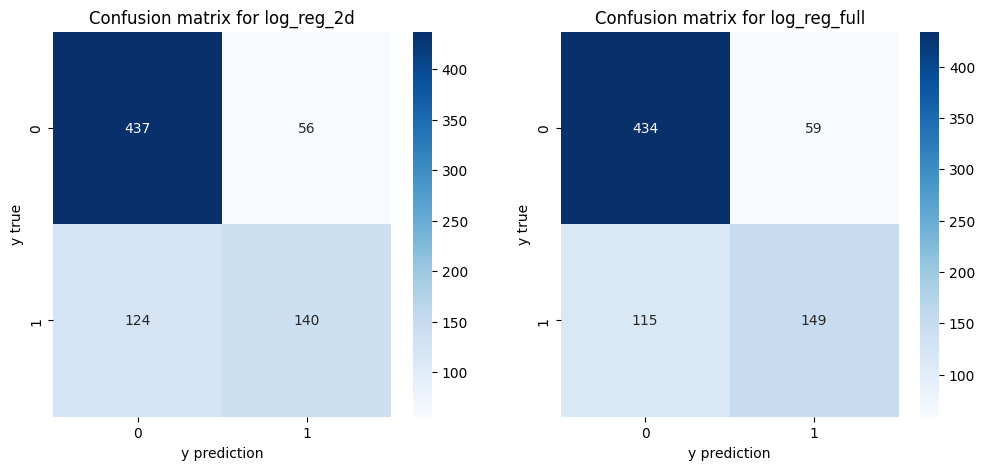

In [29]:
#Делаем предсказание моделью, обученной на двух признаках 
y_pred1 = log_reg.predict(diabetes[['Glucose', 'BMI']])
#Делаем предсказание моделью, обученной на всех признаках 
y_pred2 = log_reg_full.predict(diabetes.drop('Outcome', axis=1))
#Строим матрицы ошибок для каждой из моделей
confusion_matrix1 = metrics.confusion_matrix(y, y_pred1)
confusion_matrix2 = metrics.confusion_matrix(y, y_pred2)
#Визуализируем матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(12, 5)) #фигура + 2 координатные плоскости
#Строим тепловую карту для первой матрицы ошибок
sns.heatmap(confusion_matrix1, annot=True, fmt='', ax=axes[0], cmap='Blues')
#Добавляем название графику и подписи осей абсцисс и ординат
axes[0].set_title('Confusion matrix for log_reg_2d')
axes[0].set_xlabel('y prediction')
axes[0].set_ylabel('y true')
#Строим тепловую карту для второй матрицы ошибок
sns.heatmap(confusion_matrix2, annot=True, fmt='', ax=axes[1], cmap='Blues')
#Добавляем название графику и подписи осей абсцисс и ординат
axes[1].set_title('Confusion matrix for log_reg_full')
axes[1].set_xlabel('y prediction')
axes[1].set_ylabel('y true');

In [30]:
#Модель log_reg_2d:
#Рассчитываем accuracy
print('Accuracy: {:.2f}'.format(metrics.accuracy_score(y, y_pred1)))
#Рассчитываем precision
print('Precision: {:.2f}'.format(metrics.precision_score(y, y_pred1)))
#Рассчитываем recall
print('Recall: {:.2f}'.format(metrics.recall_score(y, y_pred1)))
#Рассчитываем F1-меру
print('F1 score: {:.2f}'.format(metrics.f1_score(y, y_pred1)))

Accuracy: 0.76
Precision: 0.71
Recall: 0.53
F1 score: 0.61


In [31]:
#Модель log_reg_full:
#Рассчитываем accuracy
print('Accuracy: {:.2f}'.format(metrics.accuracy_score(y, y_pred2)))
#Рассчитываем precision
print('Precision: {:.2f}'.format(metrics.precision_score(y, y_pred2)))
#Рассчитываем recall
print('Recall: {:.2f}'.format(metrics.recall_score(y, y_pred2)))
#Рассчитываем F1-меру
print('F1 score: {:.2f}'.format(metrics.f1_score(y, y_pred2)))

Accuracy: 0.77
Precision: 0.72
Recall: 0.56
F1 score: 0.63


In [32]:
print(metrics.classification_report(y, y_pred2))

              precision    recall  f1-score   support

           0       0.79      0.88      0.83       493
           1       0.72      0.56      0.63       264

    accuracy                           0.77       757
   macro avg       0.75      0.72      0.73       757
weighted avg       0.76      0.77      0.76       757



In [34]:
#Считаем вероятности наличия диабета для каждого из пациентов
#Нас интересует только вероятность класса (второй столбец)
y_proba_pred = log_reg_full.predict_proba(diabetes.drop('Outcome', axis=1))[:, 1]
#Для удобства завернём numpy-массив в Pandas Series
y_proba_pred = pd.Series(y_proba_pred)
#Создадим списки, в которых будем хранить значения метрик 
recall_scores = []
precision_scores = []
f1_scores = []
#Сгенерируем набор вероятностных порогов в диапазоне от 0.1 до 1
thresholds = np.arange(0.1, 1, 0.05)
#В цикле будем перебирать сгенерированные пороги
for threshold in thresholds:
    #Пациентов, для которых вероятность наличия диабета > threshold, относим к классу 1
    #В противном случае — к классу 0
    y_pred = y_proba_pred.apply(lambda x: 1 if x>threshold else 0)
    #Считаем метрики и добавляем их в списки
    recall_scores.append(metrics.recall_score(y, y_pred))
    precision_scores.append(metrics.precision_score(y, y_pred))
    f1_scores.append(metrics.f1_score(y, y_pred))

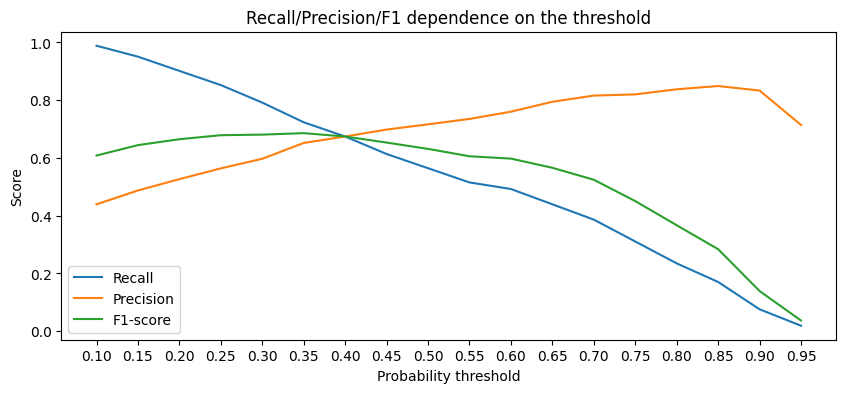

In [35]:
#Визуализируем метрики при различных threshold
fig, ax = plt.subplots(figsize=(10, 4)) #фигура + координатная плоскость
#Строим линейный график зависимости recall от threshold
ax.plot(thresholds, recall_scores, label='Recall')
#Строим линейный график зависимости precision от threshold
ax.plot(thresholds, precision_scores, label='Precision')
#Строим линейный график зависимости F1 от threshold
ax.plot(thresholds, f1_scores, label='F1-score')
 
#Даём графику название и подписываем оси
ax.set_title('Recall/Precision/F1 dependence on the threshold')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Score')
#Устанавливаем отметки по оси x
ax.set_xticks(thresholds) 
#Отображаем легенду
ax.legend();

In [36]:
#Задаём оптимальный порог вероятностей
threshold_opt = 0.4
#Пациентов, для которых вероятность наличия диабета > 0.4, относим к классу 1
#В противном случае — к классу 0
y_pred_opt = y_proba_pred.apply(lambda x: 1 if x > threshold_opt else 0)
#Считаем метрики
print(metrics.classification_report(y, y_pred_opt))

              precision    recall  f1-score   support

           0       0.83      0.83      0.83       493
           1       0.67      0.67      0.67       264

    accuracy                           0.77       757
   macro avg       0.75      0.75      0.75       757
weighted avg       0.77      0.77      0.77       757



ABOP

In [41]:
y_true_0 = [0, 0, 1, 1, 1, 1, 0, 1]
y_pred_0 = [0, 1, 0, 0, 1, 1, 0, 1]
# precision
print("Precision:", metrics.precision_score(y_true_0, y_pred_0))
#
y_true_1 = [0, 0, 1, 1, 1, 1, 0, 1]
y_pred_1 = [0, 1, 0, 0, 1, 1, 0, 1]
# recall
print('Recall:', metrics.recall_score(y_true_1, y_pred_1))
#
y_true_2 = [0, 0, 1, 1, 1, 1, 0, 1]
y_pred_2 = [0, 1, 0, 0, 1, 1, 0, 1]
# F1 score
print('F1 score:', round(metrics.f1_score(y_true_2, y_pred_2), 2))

Precision: 0.75
Recall: 0.6
F1 score: 0.67
